# Module 5 — Learning Representations from Images and Text

## Lesson 5.6 — Synthesis: Putting Representation Learning into Practice


This final note of Module 5 brings everything together in one careful experiment. We return to the question we started with in Note 5.1, *what changes when a network learns its own representation?*, but now we have a CNN that respects the structure of images, and we have learned to be suspicious of pictures that are not backed by numbers.

The plan is simple. We take the same Fashion-MNIST images and describe them in three ways: as **raw pixels**, as features learned by an **MLP encoder**, and as features learned by a **CNN encoder**. Then we ask each representation the same questions:

- How well does a simple linear classifier do on top of it?
- Are the differences real, or could they be luck?
- Which classes benefit, and which do not?
- Do images that are close in the representation actually belong to the same class?
- And what do 2D pictures of the representations, made with PCA and t-SNE, show, and what do they hide?

There are no new architectures in this note. It is about **evaluating representations properly**, a skill you will use every time you choose between pretrained models in Module 7.

**Key question:** *How can we measure, rather than just eyeball, what a learned representation has gained over raw data?*

### Learning objectives
- compare representations fairly with linear probes and a sign test;
- break a comparison down by class to see where a representation helps;
- use nearest neighbours to check whether a representation groups similar items together;
- make PCA and t-SNE pictures of a representation, and back them up with numbers;
- explain what t-SNE preserves and what it does not.

### Prerequisites

 read Notes 5.1 and 5.2. You should be comfortable with linear probes, CNNs and the sign test.

### Setup

Run this cell first. Besides PyTorch, we use several tools from scikit-learn: logistic regression for linear probes, k-nearest-neighbour classifiers, cross-validation, and the two visualisation methods PCA and t-SNE.

**Environment and results.** The saved outputs record one CPU reference run; random seeds reduce variation but do not guarantee identical numbers across computers. Read the comparisons as evidence from that run. Training times depend on your hardware.

If packages are missing, install them into your notebook environment, then restart the kernel and run from the beginning:

```text
%pip install torch==2.14.1 numpy==2.5.4 pandas==3.0.6 matplotlib==3.11.2 scikit-learn==1.9.1 scipy==1.18.1
```

In [1]:
import os, gzip, urllib.request, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

torch.manual_seed(0)
np.random.seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## 1. Comparing Raw Inputs and Learned Features

### 1.1 The experimental setup

To compare representations fairly, we reuse the three-way split from Note 5.1. Each group of images has one job, and no image is used for more than one job:

In [2]:
DATA_DIR = "data/fashion"
BASE_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"]
os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES:
    if not os.path.exists(os.path.join(DATA_DIR, f)):
        urllib.request.urlretrieve(BASE_URL + f, os.path.join(DATA_DIR, f))
def read_idx(f, offset):
    with gzip.open(os.path.join(DATA_DIR, f)) as fh:
        return np.frombuffer(fh.read(), dtype=np.uint8, offset=offset)
X = torch.tensor(read_idx(FILES[0], 16).reshape(-1, 1, 28, 28), dtype=torch.float32) / 255.0
y = torch.tensor(read_idx(FILES[1], 8).astype(np.int64))
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
rep_idx, probe_idx, val_idx = np.arange(0, 40000), np.arange(40000, 50000), np.arange(50000, 60000)
print("learn representations on:", len(rep_idx), "| train downstream classifiers on:", len(probe_idx),
      "| measure on:", len(val_idx))

learn representations on: 40000 | train downstream classifiers on: 10000 | measure on: 10000


- **40,000 images** are used only to train the two encoders, so that they learn their representations.
- **10,000 images** are used to train the downstream classifiers (the linear probes) and as the reference set for nearest neighbours.
- **10,000 images** are held out, and every accuracy in this note is measured on them.

### 1.2 Learning the two representations

We train two encoders, each with a 10-class head on top, for 3 epochs each:

- an **MLP encoder**: flatten, then one hidden layer of 128 units, the same as in Note 5.1;
- a **CNN encoder**: the two convolution blocks from Note 5.2, followed by a fully connected layer of 64 units.

After training, we keep only the encoders and discard the heads, exactly as in Note 5.1.

In [3]:
class MLPEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU())
        self.head = nn.Linear(128, 10)
    def forward(self, x): return self.head(self.encoder(x))

class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU())        # representation: 64 numbers
        self.head = nn.Linear(64, 10)
    def forward(self, x): return self.head(self.encoder(x))

def train(model, epochs=3, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    Xt, yt = X[rep_idx], y[rep_idx]
    for epoch in range(epochs):
        perm = torch.randperm(len(Xt)); total, n = 0.0, 0
        for i in range(0, len(Xt), 128):
            b = perm[i:i+128]
            opt.zero_grad(); loss = F.cross_entropy(model(Xt[b]), yt[b]); loss.backward(); opt.step()
            total += loss.item(); n += 1
        print(f"  epoch {epoch+1}: average training loss {total/n:.3f}")
    return model

torch.manual_seed(0); print("MLP encoder"); mlp = train(MLPEncoder())
torch.manual_seed(0); print("CNN encoder"); cnn = train(CNNEncoder())

MLP encoder


  epoch 1: average training loss 0.649


  epoch 2: average training loss 0.451


  epoch 3: average training loss 0.404
CNN encoder


  epoch 1: average training loss 0.742


  epoch 2: average training loss 0.414


  epoch 3: average training loss 0.357


Both encoders learn normally: the MLP's average training loss falls from 0.649 to 0.404, and the CNN's from 0.742 to 0.357. Now we pass every image through each encoder and collect the representations.

In [4]:
def features(model, X_, bs=2000):
    model.eval()
    with torch.no_grad():
        out = torch.cat([model.encoder(X_[i:i+bs]) for i in range(0, len(X_), bs)])
    return out.numpy()

R = X.flatten(1).numpy()                 # raw pixels: 784 numbers per image
M = features(mlp, X)                     # MLP representation: 128 numbers
C = features(cnn, X)                     # CNN representation: 64 numbers
reps = {"raw pixels": R, "MLP features": M, "CNN features": C}
for name, Fm in reps.items():
    print(f"{name:<13} {Fm.shape[1]:>4} numbers per image")

raw pixels     784 numbers per image
MLP features   128 numbers per image
CNN features    64 numbers per image


Each image now has three descriptions: 784 raw pixel values, 128 MLP features and 64 CNN features. The CNN's description is the most compact of the three.

### 1.3 Linear probes

As in Note 5.1, we measure each representation by training the **same** simple classifier on top of it: a standardised logistic regression, trained on the 10,000 probe images and evaluated on the 10,000 validation images. Any difference in accuracy comes from the representation.

In [5]:
def linear_probe(Fm, train_idx, eval_idx):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    clf.fit(Fm[train_idx], y[train_idx].numpy())
    return clf.score(Fm[eval_idx], y[eval_idx].numpy()), clf.predict(Fm[eval_idx])

probe_acc, probe_pred = {}, {}
for name, Fm in reps.items():
    probe_acc[name], probe_pred[name] = linear_probe(Fm, probe_idx, val_idx)
    print(f"linear classifier on {name:<13} validation accuracy {probe_acc[name]:.3f}")

linear classifier on raw pixels    validation accuracy 0.803


linear classifier on MLP features  validation accuracy 0.867


linear classifier on CNN features  validation accuracy 0.882


The ranking is clear: raw pixels reach 0.803, MLP features 0.867 and CNN features 0.882. The CNN's representation is the most useful *and* the smallest.

But a difference of 0.015 between the MLP and the CNN is only 150 images out of 10,000. Could it be luck? We use the **sign test** from Note 5.2: look only at the images where two classifiers disagree, and ask whether the split could plausibly be a coin flip.

In [6]:
from scipy.stats import binomtest
yv = y[val_idx].numpy()
def sign_test(pa, pb):
    a = int(((pa == yv) & (pb != yv)).sum()); b = int(((pb == yv) & (pa != yv)).sum())
    return a, b, binomtest(a, a + b).pvalue
for A, B in [("CNN features", "raw pixels"), ("CNN features", "MLP features")]:
    a, b, p = sign_test(probe_pred[A], probe_pred[B])
    print(f"{A} vs {B}: right only with {A} {a} | right only with {B} {b} | p = {p:.2g}")
print("one validation image is worth", 1 / len(val_idx), "of accuracy")

CNN features vs raw pixels: right only with CNN features 1143 | right only with raw pixels 351 | p = 6.9e-98
CNN features vs MLP features: right only with CNN features 477 | right only with MLP features 319 | p = 2.4e-08
one validation image is worth 0.0001 of accuracy


For these fitted classifiers, the paired tests provide strong evidence of accuracy differences on this validation sample; they do not establish that every retraining will have the same ranking. Against raw pixels, the CNN-feature classifier was right on 1,143 images that the raw-pixel classifier got wrong, against only 351 the other way round (p = 6.9e-98). Against MLP features the margin is smaller but still convincing: 477 against 319 (p = 2.4e-08). With 10,000 validation images, each image is worth 0.0001 of accuracy, so even modest accuracy gaps rest on hundreds of images.

### 1.4 Where does the gain come from?

An overall accuracy hides a lot. Let's compare raw pixels and CNN features class by class.

In [7]:
print(f"{'class':<12} {'raw':>6} {'CNN':>6} {'gain':>6}")
gains = []
for c in range(10):
    m = yv == c
    r_, c_ = (probe_pred["raw pixels"][m] == c).mean(), (probe_pred["CNN features"][m] == c).mean()
    gains.append(c_ - r_)
    print(f"{CLASSES[c]:<12} {r_:>6.3f} {c_:>6.3f} {c_ - r_:>+6.3f}")

class           raw    CNN   gain
T-shirt/top   0.752  0.862 +0.110
Trouser       0.951  0.964 +0.012
Pullover      0.678  0.792 +0.114
Dress         0.802  0.914 +0.112
Coat          0.710  0.832 +0.122
Sandal        0.891  0.944 +0.053
Shirt         0.528  0.640 +0.112
Sneaker       0.907  0.948 +0.041
Bag           0.924  0.977 +0.054
Ankle boot    0.898  0.954 +0.056


The gains are very uneven. Trousers barely change (+0.012): their long two-legged shape is already obvious in raw pixels, so there is little left to gain. The biggest gains are for coats (+0.122), pullovers (+0.114), dresses and shirts (+0.112 each) and T-shirts (+0.110), the classes that look alike in outline and differ in details such as sleeves, collars and texture. Those are exactly the local patterns that convolution filters are designed to pick up.

Notice also what the learned representation did *not* fix. Shirts remain by far the hardest class, at 0.640 even with CNN features. We will look at why in Section 1.6.

### 1.5 With very few labels

In Note 5.1 we saw that good representations shine when labelled data is scarce. Let's check that the CNN representation holds up here too: we train each linear probe on just 100 labelled images, about 10 per class, repeated with 5 random draws.

In [8]:
rng = np.random.default_rng(0)
small = {name: [] for name in reps}
for _ in range(5):
    sub = rng.choice(probe_idx, 100, replace=False)
    for name, Fm in reps.items():
        small[name].append(linear_probe(Fm, sub, val_idx)[0])
for name in reps:
    print(f"100 labels, {name:<13} mean acc {np.mean(small[name]):.3f} (range {min(small[name]):.3f} to {max(small[name]):.3f})")

100 labels, raw pixels    mean acc 0.669 (range 0.613 to 0.698)
100 labels, MLP features  mean acc 0.792 (range 0.773 to 0.820)
100 labels, CNN features  mean acc 0.838 (range 0.826 to 0.850)


With 100 labels, CNN features reach 0.838 on average, against 0.792 for MLP features and 0.669 for raw pixels. The spread across the 5 draws is narrower for the CNN, too (0.826 to 0.850), than for raw pixels (0.613 to 0.698). With only 100 labels, the CNN representation already beats raw pixels trained with all 10,000 labels (0.803).

### 1.6 Are similar images close together?

A representation is a kind of map in which every image has a position. A good map should place images of the same kind close together. We can check this directly with **nearest neighbours**: for a query image, find the images whose representations are closest to it (here, by straight-line distance).

Let's start with the first four validation images, chosen by position, not because they make any representation look good:

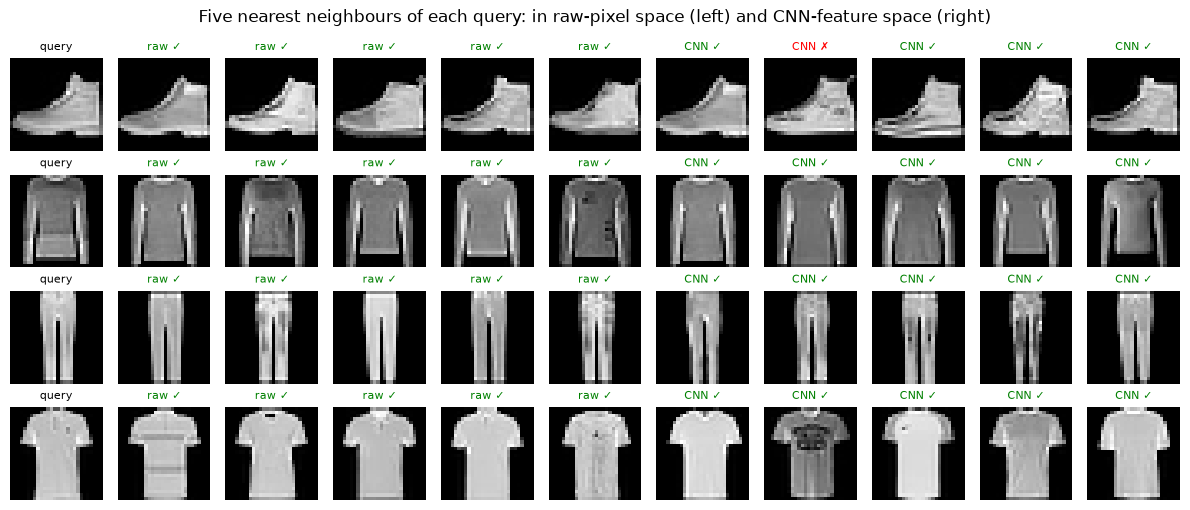

query classes: ['Ankle boot', 'Pullover', 'Trouser', 'T-shirt/top']


In [9]:
q = val_idx[[0, 1, 2, 3]]                # four query images from the validation set
def nearest(Fm, qi, k=5):
    Q = Fm[[qi]]; P = Fm[probe_idx]
    d = ((P - Q) ** 2).sum(1)            # squared distance to every image in the probe set
    return probe_idx[np.argsort(d)[:k]]

fig, axes = plt.subplots(len(q), 11, figsize=(12, 5.2))
for r, qi in enumerate(q):
    axes[r, 0].imshow(X[qi, 0], cmap="gray"); axes[r, 0].set_title("query", fontsize=8)
    for j, i in enumerate(nearest(R, qi)):
        axes[r, 1 + j].imshow(X[i, 0], cmap="gray")
        axes[r, 1 + j].set_title("raw ✓" if y[i] == y[qi] else "raw ✗", fontsize=8, color="green" if y[i] == y[qi] else "red")
    for j, i in enumerate(nearest(C, qi)):
        axes[r, 6 + j].imshow(X[i, 0], cmap="gray")
        axes[r, 6 + j].set_title("CNN ✓" if y[i] == y[qi] else "CNN ✗", fontsize=8, color="green" if y[i] == y[qi] else "red")
for ax in axes.flat: ax.axis("off")
plt.suptitle("Five nearest neighbours of each query: in raw-pixel space (left) and CNN-feature space (right)")
plt.tight_layout(); plt.show()
print("query classes:", [CLASSES[int(y[i])] for i in q])

For these four queries, an ankle boot, a pullover, a pair of trousers and a T-shirt, both spaces find almost entirely correct neighbours. The one mistake shown is a CNN neighbour of the ankle boot that is actually a sneaker. Easy images are easy in any reasonable representation.

To see a difference, we need harder cases. Shirts were the hardest class, so here are the first four validation shirts, again chosen by position, not by outcome:

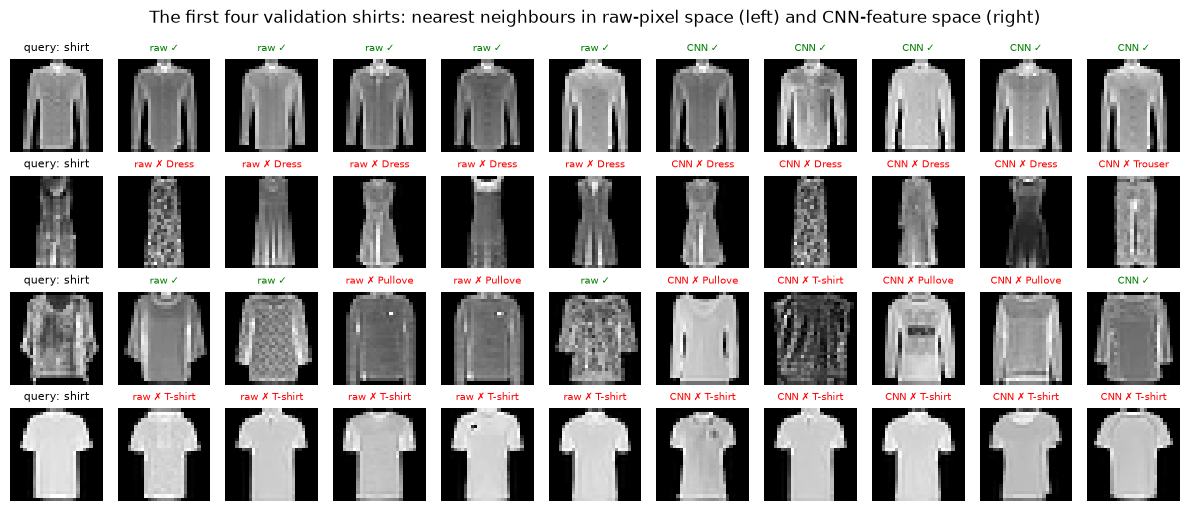

share of the 5 nearest neighbours with the same class, over 2,000 validation images:


  raw pixels 0.782 | CNN features 0.841
  same, for the first 200 validation shirts only: raw 0.542 | CNN 0.576


In [10]:
from sklearn.neighbors import NearestNeighbors
def neighbour_agreement(Fm, queries, k=5):
    nn_ = NearestNeighbors(n_neighbors=k).fit(Fm[probe_idx])
    idx = probe_idx[nn_.kneighbors(Fm[queries], return_distance=False)]   # (queries, k)
    return (y[idx] == y[queries][:, None]).float().mean().item()

shirts = val_idx[(y[val_idx] == 6).numpy()][:4]          # the first four validation shirts
fig, axes = plt.subplots(len(shirts), 11, figsize=(12, 5.2))
for r, qi in enumerate(shirts):
    axes[r, 0].imshow(X[qi, 0], cmap="gray"); axes[r, 0].set_title("query: shirt", fontsize=8)
    for off, (Fm, tag) in [(1, (R, "raw")), (6, (C, "CNN"))]:
        for j, i in enumerate(nearest(Fm, qi)):
            ok = y[i] == y[qi]
            axes[r, off + j].imshow(X[i, 0], cmap="gray")
            axes[r, off + j].set_title(f"{tag} {'✓' if ok else '✗ ' + CLASSES[int(y[i])][:7]}", fontsize=7,
                                       color="green" if ok else "red")
for ax in axes.flat: ax.axis("off")
plt.suptitle("The first four validation shirts: nearest neighbours in raw-pixel space (left) and CNN-feature space (right)")
plt.tight_layout(); plt.show()
ev_q = val_idx[:2000]
print(f"share of the 5 nearest neighbours with the same class, over 2,000 validation images:")
print(f"  raw pixels {neighbour_agreement(R, ev_q):.3f} | CNN features {neighbour_agreement(C, ev_q):.3f}")
shirt_q = val_idx[(y[val_idx] == 6).numpy()][:200]
print(f"  same, for the first 200 validation shirts only: raw {neighbour_agreement(R, shirt_q):.3f} | CNN {neighbour_agreement(C, shirt_q):.3f}")

This picture is humbling. For the first shirt, both spaces find shirts. But look at the second "shirt": it looks much more like a dress, and both spaces return dresses. The fourth looks like a T-shirt, and both spaces return T-shirts. Some of these mistakes say more about the **data** than about the representation. At 28×28 pixels, some shirts genuinely look like other garments, and no representation learned from these pixels can recover a distinction that the pixels do not contain.

The numbers below the picture put the four examples in context. Across 2,000 validation images, 0.782 of the 5 nearest neighbours share the query's class in raw-pixel space, against 0.841 in CNN space. For shirts alone the agreement is far lower in both spaces, 0.542 and 0.576. Four examples could have suggested that the CNN space is *worse* for shirts. The measurement over 200 shirts says it is slightly better, and that shirts are hard for everyone.

We can turn this neighbour idea into a classifier: **k-nearest neighbours (k-NN)** predicts a validation image's class by majority vote among its 5 nearest probe images. Its accuracy summarises how well each representation groups classes together.

In [11]:
ev = val_idx[:2000]                      # 2,000 validation images for the neighbour comparisons
knn_full = {}
for name, Fm in reps.items():
    knn = KNeighborsClassifier(5).fit(Fm[probe_idx], y[probe_idx].numpy())
    knn_full[name] = knn.score(Fm[ev], y[ev].numpy())
    print(f"5-nearest-neighbour accuracy, {name:<13} (full {Fm.shape[1]} dims): {knn_full[name]:.3f}")

5-nearest-neighbour accuracy, raw pixels    (full 784 dims): 0.828
5-nearest-neighbour accuracy, MLP features  (full 128 dims): 0.850


5-nearest-neighbour accuracy, CNN features  (full 64 dims): 0.877


The ranking is the same as for the linear probes: 0.828 for raw pixels, 0.850 for MLP features and 0.877 for CNN features. Two very different ways of using a representation, a linear classifier and a neighbour vote, agree about which one is best. These full-dimensional k-NN numbers are our reference point for the pictures that follow.

> **Common mistake:** judging a representation from a handful of examples. Four shirts could have suggested the opposite of what 200 shirts show. Always back examples with a measurement over many cases.

## 2. Visualising Learned Representations

People love to *look* at representations, and pictures can be genuinely illuminating. But a representation with 64 or 784 dimensions cannot be drawn on a flat page without throwing information away. The question is always: **how much does the picture distort?** Here we answer it with the same k-NN measurement: if a 2D picture preserved the neighbourhoods of the full representation, k-NN in the picture would be about as accurate as k-NN in the full space.

### 2.1 PCA

**Principal component analysis (PCA)** finds the two directions along which the data varies most and projects everything onto them. It is a linear projection: like casting a shadow of a 3D object onto a wall, it keeps the overall shape but flattens everything else.

In [12]:
pca_res = {}
for name in ["raw pixels", "CNN features"]:
    Fm = reps[name]
    pca = PCA(2).fit(Fm[probe_idx])
    knn = KNeighborsClassifier(5).fit(pca.transform(Fm[probe_idx]), y[probe_idx].numpy())
    pca_res[name] = (pca, knn.score(pca.transform(Fm[ev]), y[ev].numpy()))
    print(f"{name:<13} PCA keeps {pca.explained_variance_ratio_.sum():.0%} of variance | "
          f"5-NN accuracy in 2D: {pca_res[name][1]:.3f} (full dims: {knn_full[name]:.3f})")

raw pixels    PCA keeps 47% of variance | 5-NN accuracy in 2D: 0.504 (full dims: 0.828)


CNN features  PCA keeps 69% of variance | 5-NN accuracy in 2D: 0.617 (full dims: 0.877)


The 2D PCA view keeps 47% of the variance (spread) of the raw pixels and 69% of the CNN features. More importantly, look at what happens to the neighbourhoods. In 2D, k-NN accuracy drops to 0.504 for raw pixels (from 0.828 in full dimensions) and to 0.617 for CNN features (from 0.877). **The flat picture loses a large part of the structure** in both cases, so we should read it with care.

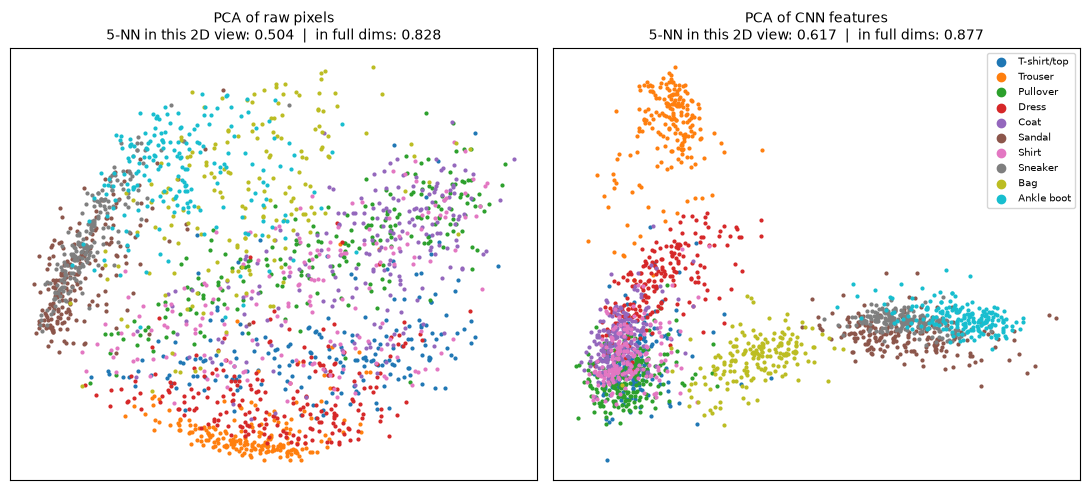

In [13]:
cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, name in zip(axes, ["raw pixels", "CNN features"]):
    pca, acc2d = pca_res[name]
    P = pca.transform(reps[name][ev])
    for c in range(10):
        m = y[ev].numpy() == c
        ax.scatter(P[m, 0], P[m, 1], s=4, color=cmap(c), label=CLASSES[c])
    ax.set_title(f"PCA of {name}\n5-NN in this 2D view: {acc2d:.3f}  |  in full dims: {knn_full[name]:.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(markerscale=3, fontsize=7, loc="best")
plt.tight_layout(); plt.show()

The CNN panel *looks* more organised: trousers, bags and footwear form clear separate groups, while all the upper-body garments are piled together in one corner. The raw-pixel panel looks like a blurred ring. That impression is consistent with the numbers: CNN features are better organised. But neither picture is a faithful map. The heavy overlap in the CNN corner does not mean those classes are inseparable; in the full 64 dimensions, a linear classifier separates them far better than the picture suggests.

### 2.2 t-SNE

**t-SNE** (t-distributed stochastic neighbour embedding) takes a different approach. Instead of projecting, it moves points around on the page, trying to keep each point's **nearest neighbours** near it. It does not try to preserve large distances. It is widely used because it produces striking, clustered pictures. t-SNE is slower than PCA and cannot place new points without re-running, so we apply it to 2,000 validation images, and we measure k-NN on those same 2,000 images with 5-fold cross-validation (train on four-fifths, test on the remaining fifth, five times), both in the t-SNE picture and in the full representation.

Note that this full-dimensional k-NN uses only 2,000 images as its reference set instead of 10,000, so its accuracies are lower than in Section 1.6. That is fine: what matters is comparing the picture with the full space *on the same images*.

In [14]:
tsne_res = {}
yev = y[ev].numpy()
for name in ["raw pixels", "CNN features"]:
    Fm = reps[name][ev]
    Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(Fm)
    acc_2d = cross_val_score(KNeighborsClassifier(5), Z, yev, cv=5).mean()
    acc_hd = cross_val_score(KNeighborsClassifier(5), Fm, yev, cv=5).mean()
    tsne_res[name] = (Z, acc_2d, acc_hd)
    print(f"{name:<13} 5-NN (5-fold, same 2,000 images): t-SNE 2D {acc_2d:.3f} | full dims {acc_hd:.3f}")

raw pixels    5-NN (5-fold, same 2,000 images): t-SNE 2D 0.769 | full dims 0.783


CNN features  5-NN (5-fold, same 2,000 images): t-SNE 2D 0.841 | full dims 0.846


This is a very different story from PCA. In the t-SNE pictures, k-NN accuracy is almost as high as in the full space: 0.769 against 0.783 for raw pixels, and 0.841 against 0.846 for CNN features. **Here, t-SNE retains class information useful to k-NN.** Similar classification accuracy does not prove that the identities of individual neighbours are preserved. This is a transductive visualisation diagnostic: t-SNE was fitted to all 2,000 points before cross-validation, so this is not an estimate of performance on unseen points. To measure neighbour preservation directly, use neighbour overlap or trustworthiness.

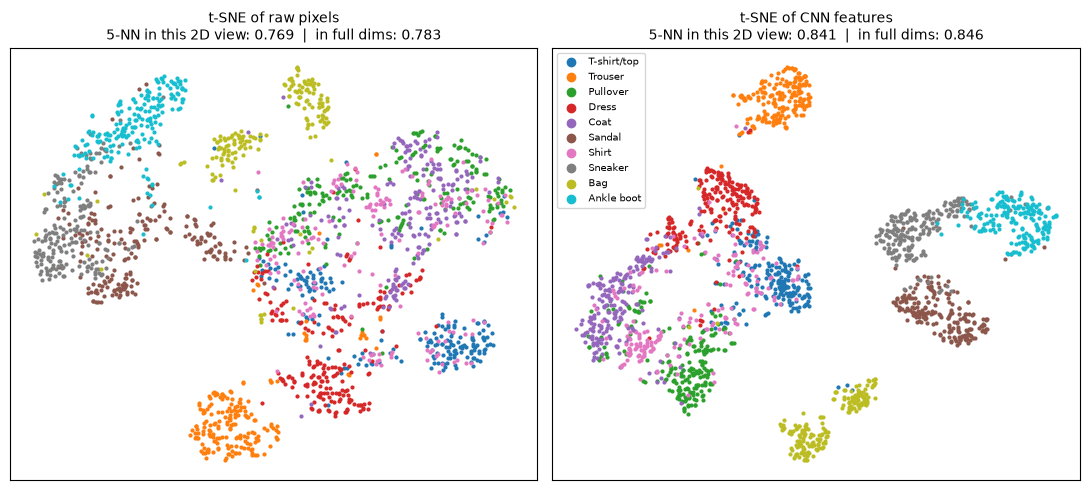

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, name in zip(axes, ["raw pixels", "CNN features"]):
    Z, a2, ah = tsne_res[name]
    for c in range(10):
        m = yev == c
        ax.scatter(Z[m, 0], Z[m, 1], s=4, color=cmap(c), label=CLASSES[c])
    ax.set_title(f"t-SNE of {name}\n5-NN in this 2D view: {a2:.3f}  |  in full dims: {ah:.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(markerscale=3, fontsize=7, loc="best")
plt.tight_layout(); plt.show()

The CNN picture shows tight, well-separated clusters for trousers, bags, sandals, sneakers and ankle boots, with the upper-body classes closer together and partly mixed. But notice that the raw-pixel picture *also* looks quite organised, much more so than its PCA picture. t-SNE is very good at making clusters visible. That is its strength, and also a reason for care: a clustered t-SNE picture on its own is not evidence that a representation is good. Here the numbers tell us which exposes more class information for this full-dimensional k-NN diagnostic (0.846 against 0.783), and the pictures only illustrate it.

### 2.3 What t-SNE does *not* preserve

If t-SNE keeps neighbourhoods, can we read the rest of the picture too, such as which clusters are far apart? Let's re-run t-SNE on the same CNN features with different random starting points and see what changes.

In [16]:
Z, _, _ = tsne_res["CNN features"]
for seed in [1, 2]:
    Z2 = TSNE(n_components=2, perplexity=30, init="random", random_state=seed).fit_transform(reps["CNN features"][ev])
    acc = cross_val_score(KNeighborsClassifier(5), Z2, yev, cv=5).mean()
    centres = np.array([Z2[yev == c].mean(0) for c in range(10)])
    far = np.argmax(((centres[:, None] - centres[None]) ** 2).sum(-1).flatten())
    print(f"t-SNE random start, seed {seed}: 5-NN {acc:.3f} | most distant pair of class centres:",
          CLASSES[far // 10], "and", CLASSES[far % 10])
centres = np.array([Z[yev == c].mean(0) for c in range(10)])
far = np.argmax(((centres[:, None] - centres[None]) ** 2).sum(-1).flatten())
print("t-SNE from PCA start (plot above): most distant pair of class centres:", CLASSES[far // 10], "and", CLASSES[far % 10])

t-SNE random start, seed 1: 5-NN 0.845 | most distant pair of class centres: Trouser and Sandal


t-SNE random start, seed 2: 5-NN 0.838 | most distant pair of class centres: Trouser and Bag
t-SNE from PCA start (plot above): most distant pair of class centres: Coat and Ankle boot


The class-prediction scores are similar across these runs: k-NN in the picture stays at 0.845 and 0.838, close to the 0.841 of the first run. But the **global layout is not**. The two classes whose cluster centres end up farthest apart are trousers and sandals in one run, trousers and bags in another, and coats and ankle boots in the picture above. The same data, with a different random start, gives a different arrangement of clusters.

So the rule for reading t-SNE pictures is:

- **Use as hypotheses:** local groupings that remain stable across settings; verify important neighbours in the full representation.
- **Do not trust:** distances *between* clusters, the sizes of clusters, or the empty space between them.

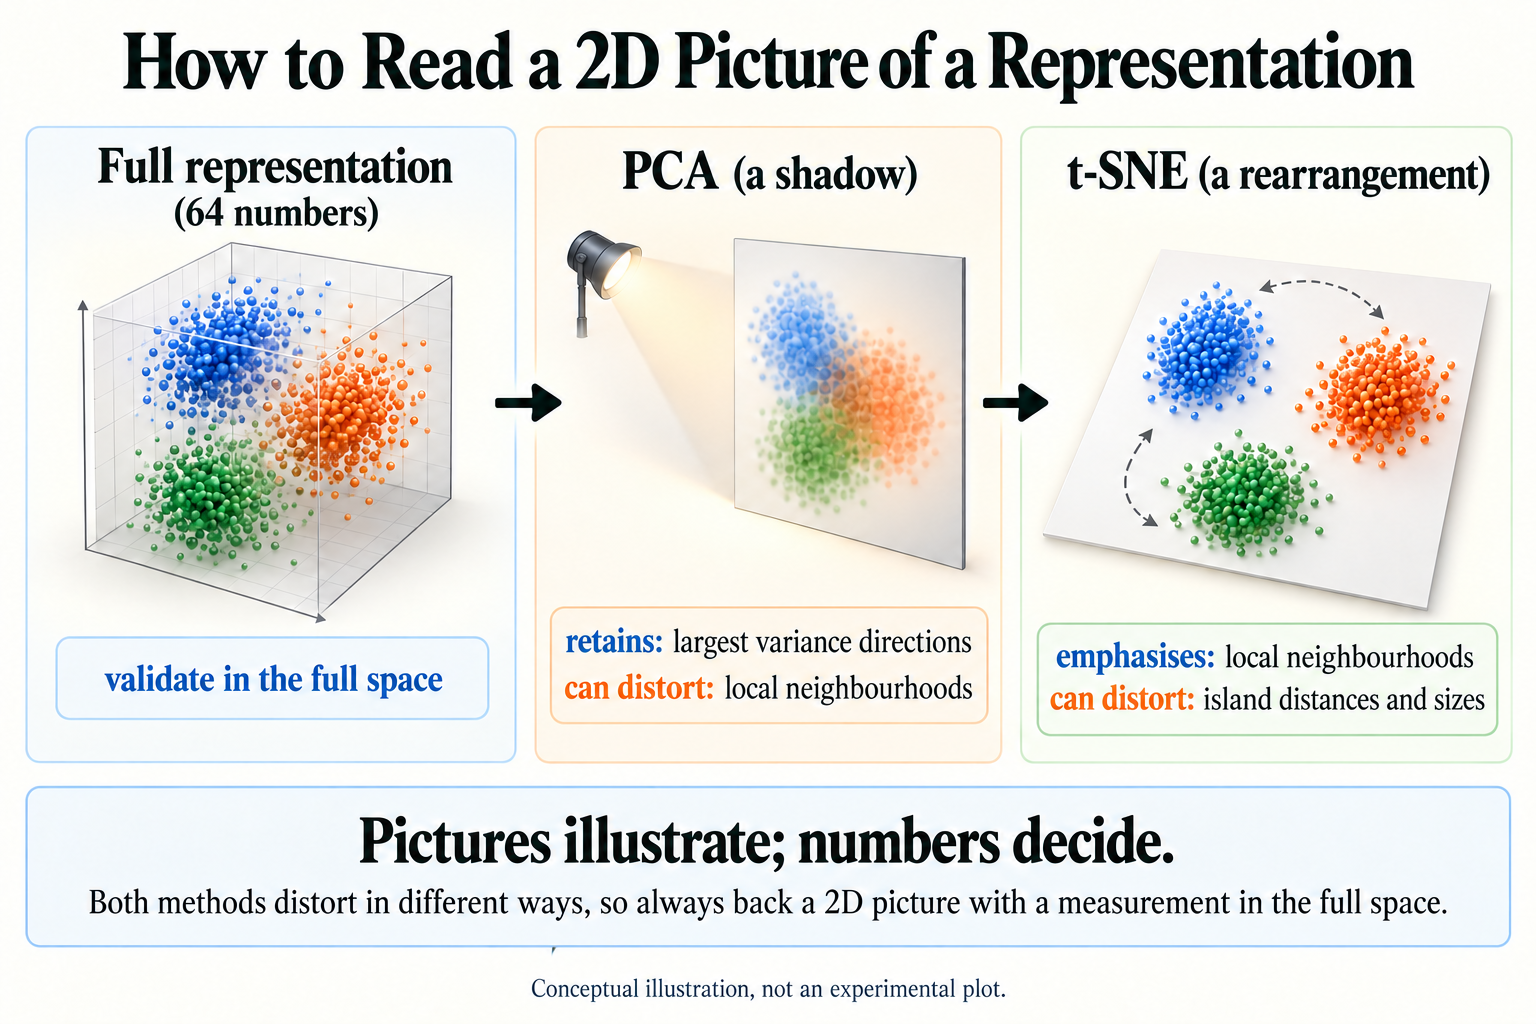

*Figure 5.6.1. Conceptual projection analogy. PCA retains directions of greatest variance; t-SNE emphasises local neighbourhoods. Both can distort structure, so validate claims using appropriate measurements in the full representation space.*

> **Common mistake:** concluding from a t-SNE plot that "class A is very different from class B because their clusters are far apart". t-SNE does not preserve distances between clusters, and the layout changes between runs. Compare distances in the full representation instead.

> **Key terms**
> - **k-nearest neighbours (k-NN):** classifying an item by majority vote of the k most similar items.
> - **PCA:** a linear projection onto the directions of greatest variance.
> - **Explained variance:** the share of the data's spread that a PCA projection keeps.
> - **t-SNE:** a non-linear method that arranges points in 2D to preserve each point's nearest neighbours.
> - **Cross-validation:** repeatedly splitting data into training and test parts and averaging the results.

**Check yourself.**

1. In Section 2.1, PCA of the CNN features kept 69% of the variance, but k-NN accuracy fell from 0.877 to 0.617. How can a picture keep most of the variance yet lose so much of the neighbourhood structure?

<details>
<summary>Worked answer</summary>

Variance measures overall spread, which is dominated by the biggest differences in the data, such as "footwear vs. trousers vs. tops". PCA keeps those large directions, which accounts for most of the variance. But the finer distinctions that decide which class a point's *nearest* neighbours belong to, such as shirt vs. pullover, live in the many smaller directions that PCA throws away. So the picture keeps the big shape while scrambling many local neighbourhoods.

</details>

## 3. Summary: What Changes When a Network Learns Representations?

Let's step back and answer the question that has run through all of Module 5.

**The description changes, and the description decides what is easy.** Raw data such as pixels and characters is complete but unhelpful: individual values mean little, and important patterns are spread across many of them. A learned representation re-describes each example in terms of features that matter for a task. In this note, the same linear classifier went from 0.803 on raw pixels to 0.882 on 64 CNN features, a difference confirmed by a sign test (p = 6.9e-98).

**The architecture shapes what can be learned.** The CNN's representation beat the MLP's (0.882 against 0.867, p = 2.4e-08) while using half as many numbers, because convolution builds in the knowledge that nearby pixels matter. That same idea runs through the module: CNNs for images, embeddings for words, recurrence and then attention for sequences. Each design encodes an assumption about the data.

**The objective shapes what is learned.** In Note 5.3, the same embedding layer learned a sentiment axis or a map of word usage depending purely on the training objective. In Note 5.5, contrastive learning shaped two encoders so that images and text shared a space. A representation is always good *for something*.

**Good representations save labels.** With 100 labels, CNN features (0.838) beat raw pixels with 10,000 labels (0.803). This is the reason pretrained models matter so much: someone else has already spent the data and compute to learn a good representation, and you can reuse it.

**Not everything can be learned away.** Some shirts look like dresses or T-shirts at this resolution, and no representation could fix that (5-NN agreement for shirts: 0.542 raw, 0.576 CNN). Representation learning extracts what is in the data; it cannot invent what is not.

**Evaluate with numbers, illustrate with pictures.** Linear probes, k-NN, per-class breakdowns and sign tests told us what was true. PCA pictures lost much of the structure (k-NN 0.617 against 0.877), and t-SNE retained similar class-prediction scores in this transductive diagnostic (0.841 against 0.846) but not the layout between clusters, which changed from run to run.

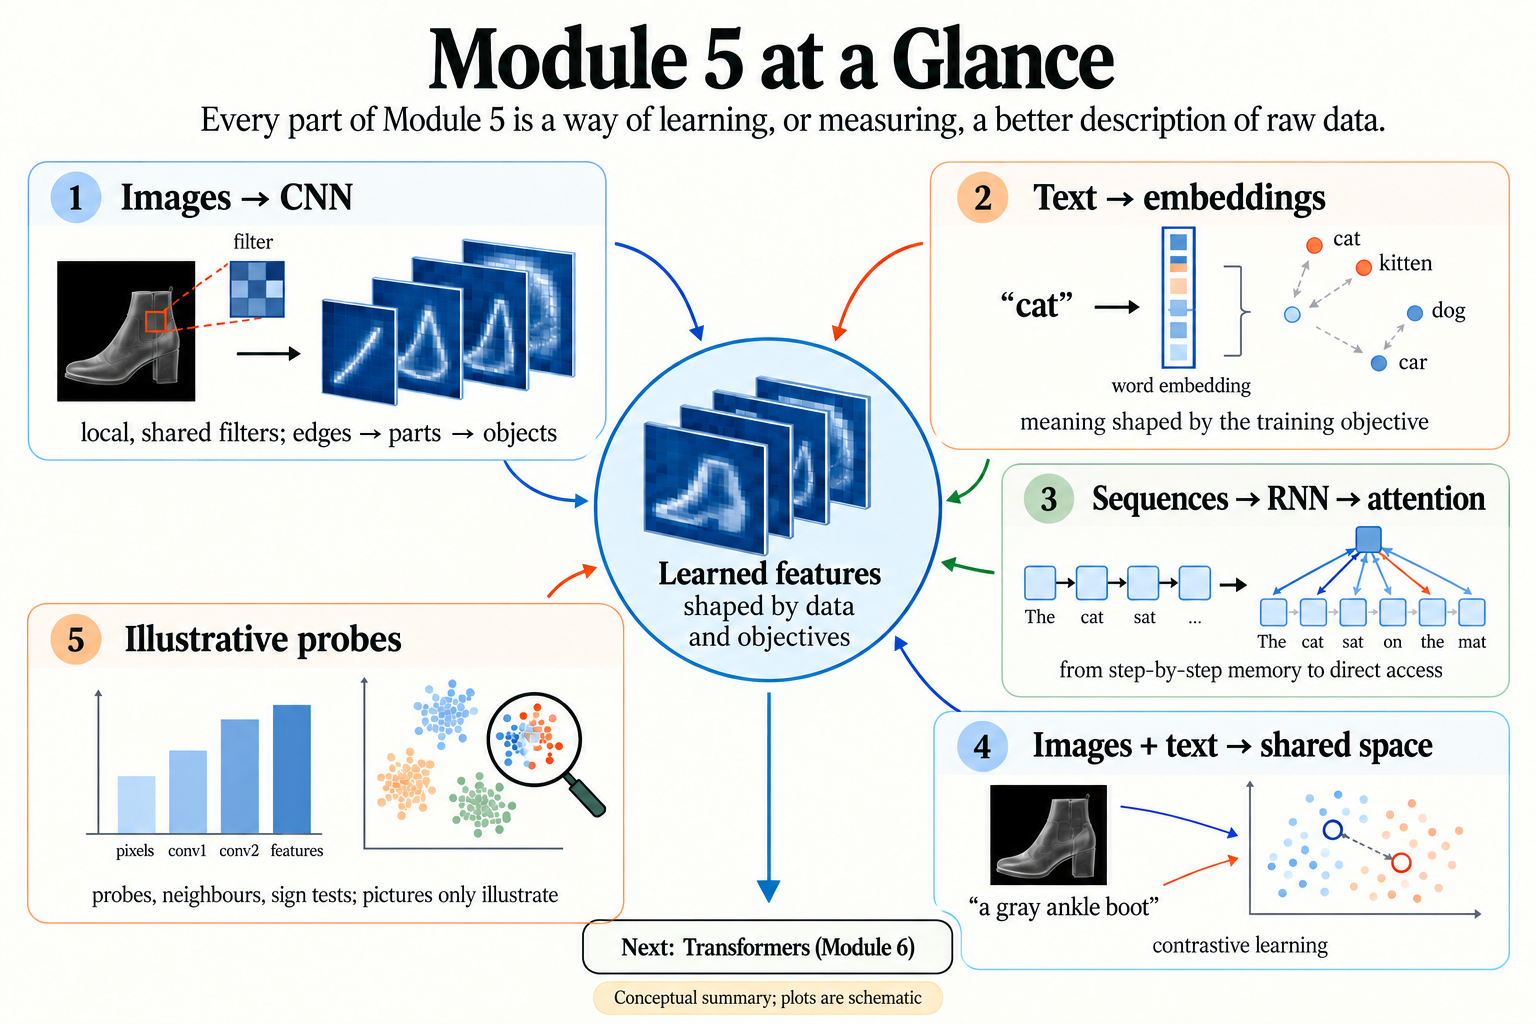

*Figure 5.6.2. Module 5 connects representation learning for images, text and sequences with shared spaces and measurement. A learned representation need not be compact or have individually interpretable coordinates.*

**Where this leads.** Module 6 takes the attention idea from Note 5.4 and builds it into the **Transformer**, the architecture that produces contextual representations for text, and, as Vision Transformers, for images too. Modules 7 and 8 then show how to reuse and adapt representations that have already been learned at enormous scale.

## Glossary

| Term | Meaning |
|---|---|
| Representation | The description of an example that a model works from. |
| Encoder | The part of a network that produces a representation. |
| Linear probe | A simple linear classifier trained on a fixed representation to measure its usefulness. |
| Sign test | Comparing two classifiers using only the examples on which they disagree. |
| Per-class accuracy | Accuracy computed separately for each class. |
| Nearest neighbours | The items whose representations are closest to a query item. |
| k-NN | k-nearest neighbours: predicting by majority vote of the k closest items. |
| Neighbour agreement | The share of an item's nearest neighbours that have the same class. |
| PCA | Principal component analysis: a linear projection onto the directions of greatest variance. |
| Explained variance | The share of the data's spread kept by a projection. |
| t-SNE | A non-linear 2D layout that preserves local neighbourhoods but not global distances. |
| Cross-validation | Averaging results over several train/test splits of the same data. |